# Project 2 – Neural network: training, LIME/SHAP analysis and latent space

**Dataset:** BRFSS 2015 diabetes health indicators, `diabetes_012` version (imbalanced). We predict whether a person has **prediabetes or diabetes** from 21 health-indicator features.

**Outline:**
1. Setup
2. Data: load, binary target, split, scaling, class weights
3. Train the neural network (21 → 32 → 16 → 1) with early stopping, then test
4. Build the LIME explainer
5. Explain a single prediction with LIME
6. LIME: no-diabetes prediction for contrast
7. LIME: stability across random seeds
8. LIME: aggregate weights for a pseudo-global view
9. SHAP (DeepExplainer): single-instance and global explanations
10. LIME vs SHAP: side-by-side comparison, fidelity, false negative vs true positive
11. Latent space: PCA, t-SNE and UMAP of the last hidden layer

### What changed compared to Project 1
Only three things were changed. Everything else (split, scaling, model, optimiser, early stopping, LIME and SHAP settings) is the same as in Project 1.

1. **Dataset**: `diabetes_012_health_indicators_BRFSS2015.csv` is used instead of the 50/50 file. The label `Diabetes_012` has 3 values (0 = no diabetes, 1 = prediabetes, 2 = diabetes). The assignment asks us to predict *prediabetes or diabetes*, so the binary target is `Diabetes_binary = 1 if Diabetes_012 > 0`. The models are therefore still binary classifiers, exactly like in Project 1.
2. **Class imbalance**: this dataset is not balanced (roughly 84 % / 16 %), so **class weights** are added to the loss (see section 2.4).
3. **New section (latent space)**: PCA, t-SNE and UMAP of the model's internal representation.

The original 3-class label `Diabetes_012` is kept on the side and is only used to colour the latent-space plots.

## 1. Setup

In [1]:
%pip install lime shap umap-learn torch scikit-learn pandas numpy matplotlib scipy --quiet

Note: you may need to restart the kernel to use updated packages.


In [2]:
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MODEL_TAG = 'NN'   # used in plot titles and file names

## 2. Data
### 2.1 Load the data and make the binary target

In [3]:
# Loads the dataset
df = pd.read_csv("diabetes_012_health_indicators_BRFSS2015.csv")

print("Dataset shape:", df.shape)
display(df.head())

print("\nOriginal 3-class label (0 = no diabetes, 1 = prediabetes, 2 = diabetes):")
print(df["Diabetes_012"].value_counts().sort_index())

Dataset shape: (253680, 22)


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0



Original 3-class label (0 = no diabetes, 1 = prediabetes, 2 = diabetes):
Diabetes_012
0.0    213703
1.0      4631
2.0     35346
Name: count, dtype: int64


In [4]:
# The task: does the person have prediabetes OR diabetes?  (Diabetes_012 = 1 or 2  ->  1)
df["Diabetes_binary"] = (df["Diabetes_012"] > 0).astype(float)

TARGET = "Diabetes_binary"
FEATURE_COLS = [c for c in df.columns if c not in ["Diabetes_012", TARGET]]
feature_names = FEATURE_COLS
class_names = ['No diabetes', 'Prediabetes/Diabetes']
pos_label = 1   # index of the positive class

print("Number of features:", len(FEATURE_COLS))
print("\nBinary target distribution:")
print(df[TARGET].value_counts().sort_index())

Number of features: 21

Binary target distribution:
Diabetes_binary
0.0    213703
1.0     39977
Name: count, dtype: int64


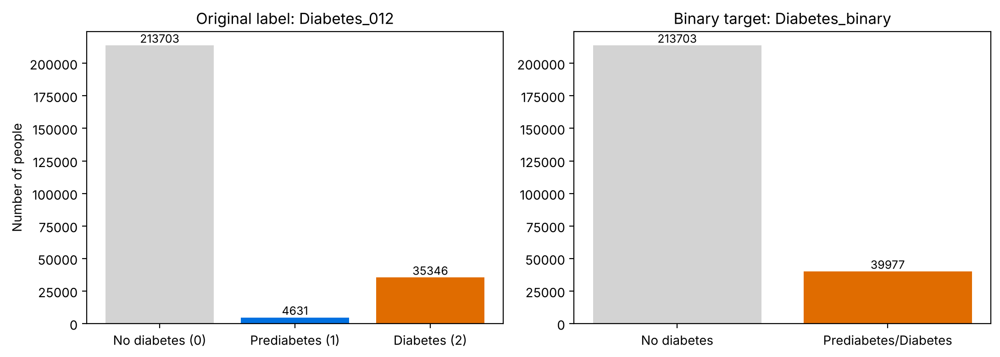

Share of positives (prediabetes or diabetes): 15.8%


In [5]:
# How imbalanced is the data?
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

counts_012 = df['Diabetes_012'].value_counts().sort_index()
axes[0].bar(['No diabetes (0)', 'Prediabetes (1)', 'Diabetes (2)'], counts_012.values,
            color=['lightgray', '#0070e0', '#e06c00'])
axes[0].set_title('Original label: Diabetes_012')
axes[0].set_ylabel('Number of people')

counts_bin = df[TARGET].value_counts().sort_index()
axes[1].bar(class_names, counts_bin.values, color=['lightgray', '#e06c00'])
axes[1].set_title(f'Binary target: {TARGET}')

for ax in axes:
    for p in ax.patches:
        ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

print(f'Share of positives (prediabetes or diabetes): {df[TARGET].mean():.1%}')

### 2.2 Train / validation / test split
Same protocol as Project 1: 20 % is kept completely separate for final testing, then 20 % of the rest is used as a validation set for early stopping. The split is stratified on the binary target.

The original 3-class label `y012` is split together with the data (same rows), so we can use it later for the latent-space plots.

In [6]:
# Separate features and target
X = df[FEATURE_COLS].to_numpy(dtype=np.float32)
y = df[TARGET].to_numpy(dtype=np.float32)
y012 = df["Diabetes_012"].to_numpy(dtype=int)   # only used to colour the latent-space plots

# Keep 20% completely separate for final testing
X_train_raw, X_test_raw, y_train, y_test, y012_train, y012_test = train_test_split(
    X, y, y012,
    test_size=0.20,
    random_state=SEED,
    stratify=y   # keeps approximately the same proportion of classes in both sets
)

# Make a validation set from the remaining data
X_train_raw, X_val_raw, y_train, y_val, y012_train, y012_val = train_test_split(
    X_train_raw, y_train, y012_train,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train
)

print(f'Train: {X_train_raw.shape}, Validation: {X_val_raw.shape}, Test: {X_test_raw.shape}')
print(f'Share of positives  train: {y_train.mean():.3f}   val: {y_val.mean():.3f}   test: {y_test.mean():.3f}')

Train: (162355, 21), Validation: (40589, 21), Test: (50736, 21)
Share of positives  train: 0.158   val: 0.158   test: 0.158


### 2.3 Standardization
Mean and standard deviation are computed on the training data only. If we used all the data, information from the test set would leak into training. The unscaled `*_raw` arrays are kept for LIME and for the plots.

In [7]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw).astype(np.float32)
X_val = scaler.transform(X_val_raw).astype(np.float32)
X_test = scaler.transform(X_test_raw).astype(np.float32)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (162355, 21)
Validation: (40589, 21)
Test: (50736, 21)


### 2.4 Class weights (new in Project 2)
With about 84 % negatives, an unweighted loss lets the network get a low loss by mostly predicting "No diabetes".
`BCEWithLogitsLoss` has a `pos_weight` argument that multiplies the loss of every **positive** example. We use

$$\text{pos\_weight} = \frac{\#\text{negatives in train}}{\#\text{positives in train}}$$

so that both classes contribute equally to the total loss. This is the same ratio as `class_weight='balanced'` in the logistic regression notebook. The weight is computed on the **training set only**.

In [8]:
n_neg = int(np.sum(y_train == 0))
n_pos = int(np.sum(y_train == 1))
pos_weight = n_neg / n_pos

print(f'Negatives in train: {n_neg}')
print(f'Positives in train: {n_pos}')
print(f'pos_weight = {n_neg} / {n_pos} = {pos_weight:.3f}')

Negatives in train: 136769
Positives in train: 25586
pos_weight = 136769 / 25586 = 5.345


In [9]:
# Convert data to PyTorch tensors
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)

X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32).view(-1, 1)

X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

batch_size = 256

train_loader = DataLoader(
    TensorDataset(X_train_t, y_train_t),
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(X_val_t, y_val_t),
    batch_size=batch_size,
    shuffle=False
)

## 3. Train the neural network
Same architecture, optimiser and early stopping as in Project 1. The only difference is `pos_weight` in the loss.

In [10]:
# This is our neural network (small and simple)

class DiabetesNN(nn.Module):
    def __init__(self, n_features):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(n_features, 32),
            nn.ReLU(),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.network(x)


model = DiabetesNN(n_features=X_train.shape[1])

# BCEWithLogitsLoss already includes the sigmoid operation internally (BCE = Binary Cross Entropy)
# pos_weight gives the positive class more weight in the loss (class imbalance)
criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight], dtype=torch.float32))
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [11]:
# Train the model with simple early stopping

max_epochs = 100   # 1 epoch = the network has seen every training observation once
patience = 5       # if validation loss doesn't improve for 5 epochs in a row, stop training

best_val_loss = float("inf")
epochs_without_improvement = 0
best_model_state = None

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(max_epochs):

    # ----- Training -----
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()

        logits = model(X_batch)
        loss = criterion(logits, y_batch)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * X_batch.size(0)

        predictions = (torch.sigmoid(logits) >= 0.5).float()
        correct += (predictions == y_batch).sum().item()
        total += y_batch.size(0)

    train_loss = running_loss / total
    train_accuracy = correct / total

    # ----- Validation -----
    model.eval()
    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            running_val_loss += loss.item() * X_batch.size(0)

            predictions = (torch.sigmoid(logits) >= 0.5).float()
            correct += (predictions == y_batch).sum().item()
            total += y_batch.size(0)

    val_loss = running_val_loss / total
    val_accuracy = correct / total

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch {epoch + 1:02d} | "
        f"train loss: {train_loss:.4f} | "
        f"val loss: {val_loss:.4f} | "
        f"train acc: {train_accuracy:.3f} | "
        f"val acc: {val_accuracy:.3f}"
    )

    # ----- Early stopping -----
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch + 1}")
            break

# Use the weights from the epoch with the lowest validation loss
model.load_state_dict(best_model_state)

Epoch 01 | train loss: 0.8992 | val loss: 0.8643 | train acc: 0.716 | val acc: 0.697


Epoch 02 | train loss: 0.8649 | val loss: 0.8595 | train acc: 0.713 | val acc: 0.709


Epoch 03 | train loss: 0.8617 | val loss: 0.8579 | train acc: 0.715 | val acc: 0.706


Epoch 04 | train loss: 0.8601 | val loss: 0.8588 | train acc: 0.714 | val acc: 0.703


Epoch 05 | train loss: 0.8592 | val loss: 0.8581 | train acc: 0.715 | val acc: 0.725


Epoch 06 | train loss: 0.8584 | val loss: 0.8589 | train acc: 0.716 | val acc: 0.733


... (9 outputs left out)

Epoch 16 | train loss: 0.8535 | val loss: 0.8589 | train acc: 0.719 | val acc: 0.722


Epoch 17 | train loss: 0.8535 | val loss: 0.8581 | train acc: 0.720 | val acc: 0.707


Epoch 18 | train loss: 0.8532 | val loss: 0.8581 | train acc: 0.720 | val acc: 0.711
Early stopping at epoch 18


<All keys matched successfully>

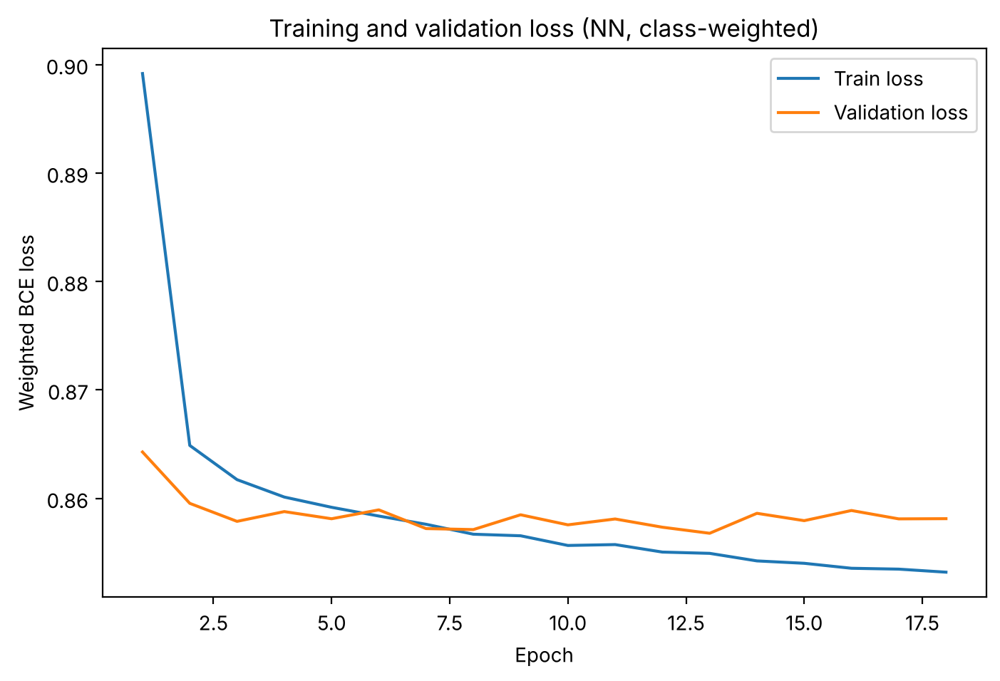

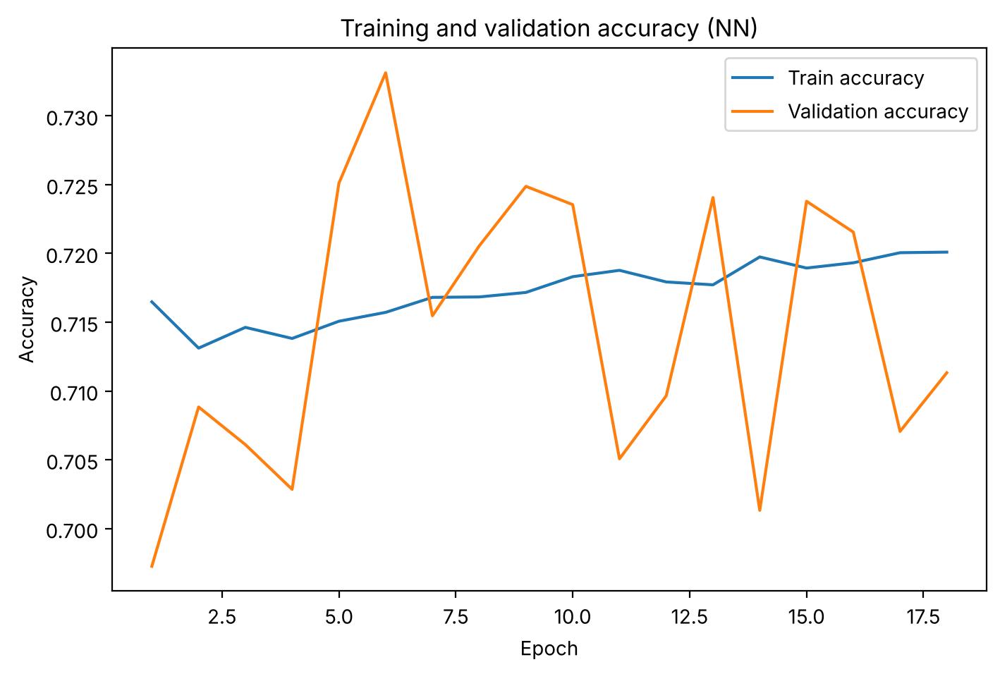

In [12]:
# Plot learning curves
epochs_run = range(1, len(train_losses) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_run, train_losses, label="Train loss")
plt.plot(epochs_run, val_losses, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Weighted BCE loss")
plt.title("Training and validation loss (NN, class-weighted)")
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs_run, train_accuracies, label="Train accuracy")
plt.plot(epochs_run, val_accuracies, label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and validation accuracy (NN)")
plt.legend()
plt.show()

### 3.1 Evaluation on the untouched test set

**Note on metrics with imbalanced data:** a model that *always* predicts "No diabetes" would already get about 84 % accuracy. Accuracy alone is therefore not a good measure here. Also look at the **recall** of the positive class, the **balanced accuracy** (the average of the recall in each class), **ROC-AUC** and **PR-AUC** (average precision). For PR-AUC, a random model scores the share of positives (about 0.16), not 0.5.

Test accuracy:          0.722
Test balanced accuracy: 0.747
ROC-AUC:                0.824
PR-AUC (avg precision): 0.460   (random model = 0.158)

Classification report:
                      precision    recall  f1-score   support

         No diabetes      0.946     0.710     0.811     42741
Prediabetes/Diabetes      0.336     0.783     0.470      7995

            accuracy                          0.722     50736
           macro avg      0.641     0.747     0.641     50736
        weighted avg      0.850     0.722     0.758     50736



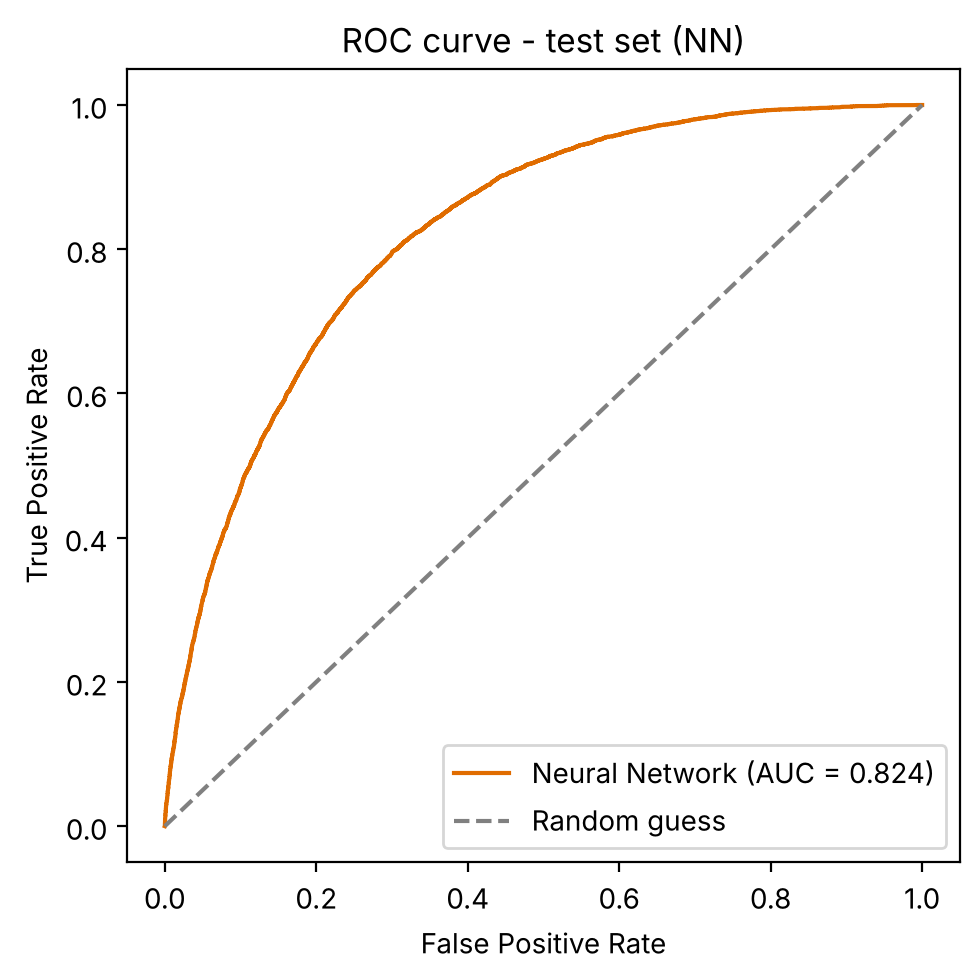

In [13]:
# Evaluation once on the untouched test set
model.eval()

with torch.no_grad():
    test_logits = model(X_test_t)
    test_probabilities = torch.sigmoid(test_logits).cpu().numpy().ravel()

test_predictions = (test_probabilities >= 0.5).astype(int)

test_accuracy = accuracy_score(y_test, test_predictions)
test_bal_acc = balanced_accuracy_score(y_test, test_predictions)
test_auc = roc_auc_score(y_test, test_probabilities)
test_ap = average_precision_score(y_test, test_probabilities)

print(f"Test accuracy:          {test_accuracy:.3f}")
print(f"Test balanced accuracy: {test_bal_acc:.3f}")
print(f"ROC-AUC:                {test_auc:.3f}")
print(f"PR-AUC (avg precision): {test_ap:.3f}   (random model = {y_test.mean():.3f})")

print("\nClassification report:")
print(classification_report(y_test, test_predictions, target_names=class_names, digits=3))

fpr_nn, tpr_nn, _ = roc_curve(y_test, test_probabilities)

plt.figure(figsize=(5, 5))
plt.plot(fpr_nn, tpr_nn, label=f'Neural Network (AUC = {test_auc:.3f})', color='#e06c00')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curve - test set (NN)')
plt.legend()
plt.tight_layout()
plt.show()

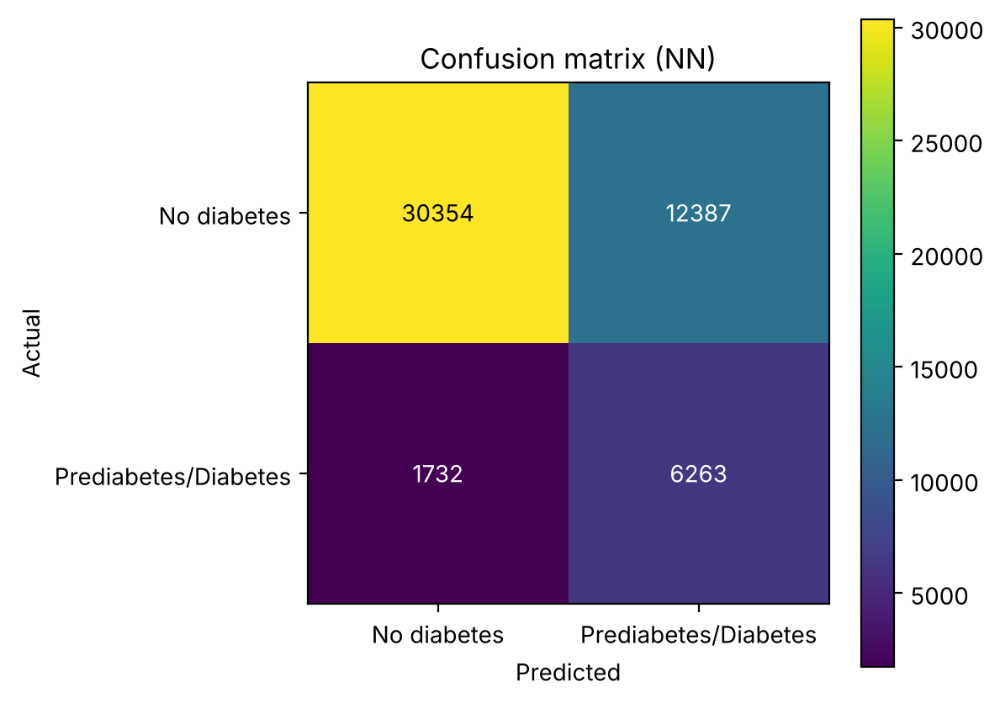

In [14]:
# Confusion matrix
cm = confusion_matrix(y_test, test_predictions)

fig, ax = plt.subplots(figsize=(5, 5))
image = ax.imshow(cm)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(class_names)
ax.set_yticklabels(class_names)

ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Confusion matrix (NN)")

for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] < cm.max() / 2 else "black")

plt.colorbar(image, ax=ax)
plt.show()

In [15]:
# Recall split by the ORIGINAL label: how many prediabetes vs diabetes cases does the model catch?
for c, name in [(1, 'Prediabetes (1)'), (2, 'Diabetes (2)')]:
    mask = y012_test == c
    recall_c = np.mean(test_predictions[mask] == 1)
    print(f'{name:16s}: {mask.sum():5d} people in test set, caught {recall_c:.1%}')

Prediabetes (1) :   906 people in test set, caught 63.6%
Diabetes (2)    :  7089 people in test set, caught 80.2%


## Explainability
Helper functions that take **unscaled** data (what LIME samples) and return class probabilities.

In [16]:
# Binary (0/1) features are treated as categorical by LIME
cat_cols = [c for c in FEATURE_COLS
            if set(np.unique(X_train_raw[:, FEATURE_COLS.index(c)])) <= {0.0, 1.0}]
num_cols = [c for c in FEATURE_COLS if c not in cat_cols]
cat_indices = [FEATURE_COLS.index(c) for c in cat_cols]

print('Categorical (binary):', cat_cols)
print('Numerical / ordinal :', num_cols)

Categorical (binary): ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']
Numerical / ordinal : ['BMI', 'GenHlth', 'MentHlth', 'PhysHlth', 'Age', 'Education', 'Income']


In [17]:
def predict_proba(X_raw_array):
    X_scaled = scaler.transform(np.asarray(X_raw_array, dtype=np.float32)).astype(np.float32)
    model.eval()
    with torch.no_grad():
        p = torch.sigmoid(model(torch.from_numpy(X_scaled))).numpy().ravel()
    return np.column_stack([1 - p, p])

def predict(X_raw_array):
    return (predict_proba(X_raw_array)[:, 1] >= 0.5).astype(int)

test_proba = predict_proba(X_test_raw)[:, 1]
test_pred = predict(X_test_raw)

print(f'Test accuracy: {accuracy_score(y_test, test_pred):.3f}')
print(f'ROC-AUC:       {roc_auc_score(y_test, test_proba):.3f}')

Test accuracy: 0.722
ROC-AUC:       0.824


## 4. Build the LIME Explainer

`LimeTabularExplainer` needs:
- `training_data`: used to learn the feature distributions for sampling (here: the **unscaled** training data)
- `feature_names`: the column names
- `class_names`: the label names
- `categorical_features`: indices of the binary columns
- `categorical_names`: maps each encoded integer to a readable string (for display)

In [18]:
import lime
import lime.lime_tabular

# Readable names for the binary features (0 = No, 1 = Yes; for Sex: 0 = female, 1 = male)
categorical_names = {}
for col in cat_cols:
    col_idx = FEATURE_COLS.index(col)
    if col == 'Sex':
        categorical_names[col_idx] = ['Female', 'Male']
    else:
        categorical_names[col_idx] = ['No', 'Yes']

explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train_raw,
    feature_names=FEATURE_COLS,
    class_names=class_names,
    categorical_features=cat_indices,
    categorical_names=categorical_names,
    mode='classification',
    random_state=42,
)
print('Explainer ready.')

Explainer ready.


## 5. Explain a single prediction

Pick one test instance and see *why* the network made its prediction.

In [19]:
# Pick the first test instance predicted as positive (prediabetes/diabetes)
diabetes_mask = test_pred == pos_label
idx = np.where(diabetes_mask)[0][0]

instance = X_test_raw[idx]
pred_proba = predict_proba(instance.reshape(1, -1))[0]
pred_class = class_names[int(pred_proba.argmax())]

print(f'Explaining instance index {idx}')
print(f'Predicted class : {pred_class}   (true class: {class_names[int(y_test[idx])]}, Diabetes_012 = {y012_test[idx]})')
print(f'Class probabilities: {dict(zip(class_names, pred_proba.round(3)))}')
pd.Series(instance, index=FEATURE_COLS).to_frame('value').T

Explaining instance index 0
Predicted class : Prediabetes/Diabetes   (true class: No diabetes, Diabetes_012 = 0)
Class probabilities: {'No diabetes': np.float32(0.327), 'Prediabetes/Diabetes': np.float32(0.673)}


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
value,1.0,0.0,1.0,31.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,0.0,9.0,4.0,5.0


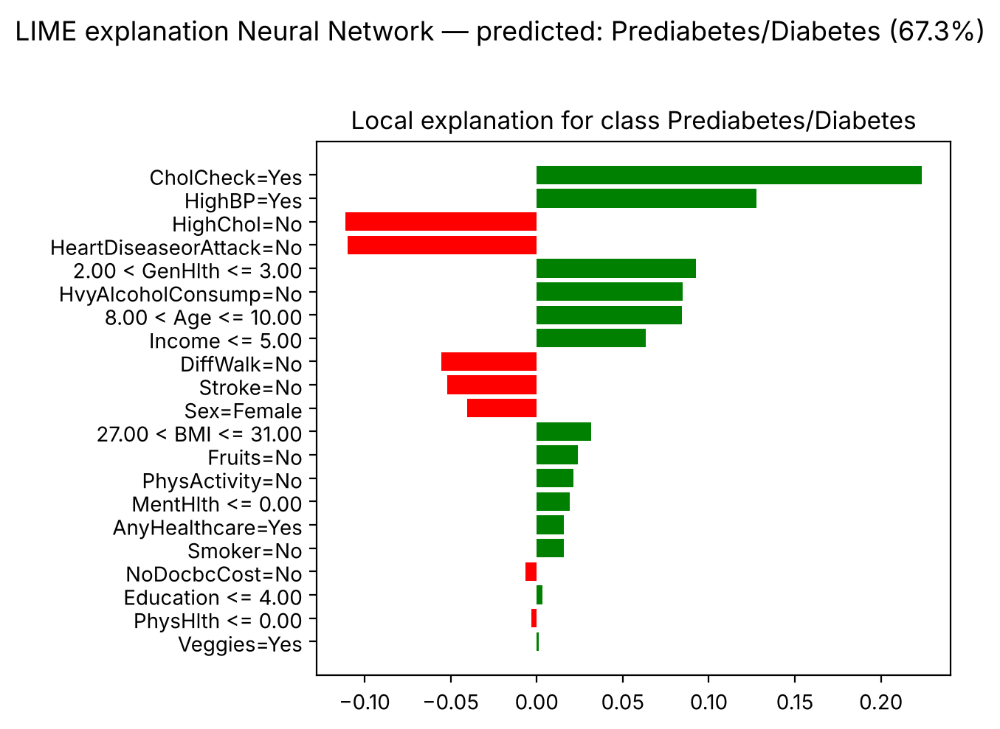

In [20]:
exp = explainer.explain_instance(
    data_row=instance,
    predict_fn=predict_proba,
    num_features=len(FEATURE_COLS),   # all 21 features in the explanation
    num_samples=5000,                 # neighbourhood samples for the surrogate
)

fig = exp.as_pyplot_figure(label=pos_label)
fig.suptitle(f'LIME explanation Neural Network — predicted: {pred_class} ({pred_proba.max():.1%})',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### Reading the plot
- **Green bars** push the prediction *toward* the positive class (prediabetes/diabetes); **red bars** push it *away*.
- Each bar is labelled with the feature condition for *this specific instance* (e.g. `HighBP=Yes`, `BMI > 33.00`).
- The x-axis is the weight of that feature in the local linear surrogate. It is not a global feature importance.

In [21]:
# Also inspect the raw weights as a DataFrame
weights = exp.as_list(label=pos_label)
pd.DataFrame(weights, columns=['feature condition', 'LIME weight']).sort_values(
    'LIME weight', key=abs, ascending=False
)

,feature condition,LIME weight
0,CholCheck=Yes,0.223603
1,HighBP=Yes,0.127786
2,HighChol=No,-0.111037
3,HeartDiseaseorAttack=No,-0.109939
4,2.00 < GenHlth <= 3.00,0.092610
5,HvyAlcoholConsump=No,0.084945
6,8.00 < Age <= 10.00,0.084476
7,Income <= 5.00,0.063331
8,DiffWalk=No,-0.055284
9,Stroke=No,-0.051830


## 6. Explain a no-diabetes prediction for contrast

Explaining instance index 20 (true class: No diabetes)


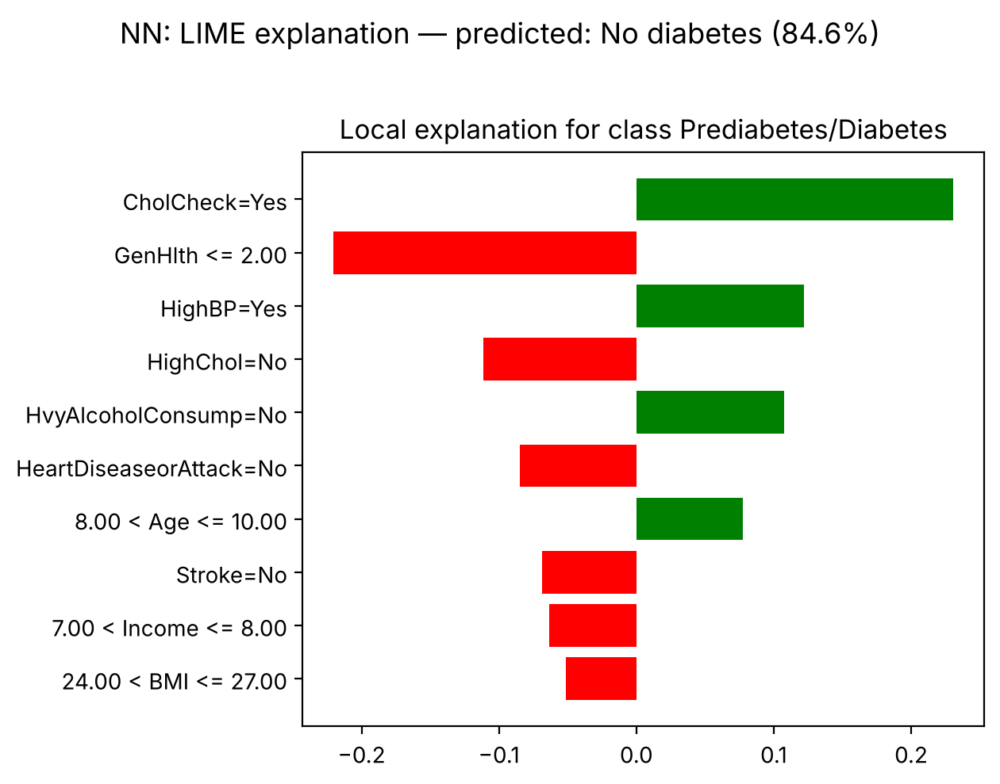

In [22]:
no_diabetes_mask = test_pred == 0
idx2 = np.where(no_diabetes_mask)[0][15]

instance2 = X_test_raw[idx2]
pred_proba2 = predict_proba(instance2.reshape(1, -1))[0]
pred_class2 = class_names[int(pred_proba2.argmax())]

exp2 = explainer.explain_instance(
    data_row=instance2,
    predict_fn=predict_proba,
    num_features=10,
    num_samples=5000,
)

print(f'Explaining instance index {idx2} (true class: {class_names[int(y_test[idx2])]})')
fig2 = exp2.as_pyplot_figure(label=pos_label)
fig2.suptitle(f'NN: LIME explanation — predicted: {pred_class2} ({pred_proba2.max():.1%})',
              fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## 7. Stability: same instance, different random seeds

LIME is stochastic, because the neighbourhood is sampled randomly.
Here we check how stable the top features are across seeds.

In [23]:
from collections import Counter

N_RUNS = 10
top_k = 5

feature_counts = Counter()
for run_seed in range(N_RUNS):
    local_exp = lime.lime_tabular.LimeTabularExplainer(
        training_data=X_train_raw,
        feature_names=FEATURE_COLS,
        class_names=class_names,
        categorical_features=cat_indices,
        categorical_names=categorical_names,
        mode='classification',
        random_state=run_seed,
    ).explain_instance(
        data_row=instance,
        predict_fn=predict_proba,
        num_features=top_k,
        num_samples=5000,
    )
    for feat_name, _ in local_exp.as_list(label=pos_label):
        feature_counts[feat_name] += 1

stability_df = pd.DataFrame(
    feature_counts.most_common(), columns=['feature condition', f'appearances (/{N_RUNS})']
)
print(stability_df.to_string(index=False))

      feature condition  appearances (/10)
          CholCheck=Yes                 10
             HighBP=Yes                 10
            HighChol=No                 10
 2.00 < GenHlth <= 3.00                 10
    8.00 < Age <= 10.00                  8
         Income <= 5.00                  1
HeartDiseaseorAttack=No                  1


Features that appear in all 10 runs are the most reliable parts of the explanation.
If a feature appears in only 2–3 runs, treat it with caution.

## 8. Aggregate LIME weights over many test instances

LIME is designed for *local* explanations, but averaging the weights over many instances gives a rough global picture of which features matter most.

Note: we map weights to features with `exp.as_map()`, which returns `(feature index, weight)` pairs. Matching on the condition string would miss conditions that start with a number, such as `24.00 < BMI <= 27.00`.

In [24]:
N_EXPLAIN = 100  # increase for smoother averages (slower)
rng = np.random.default_rng(0)
sample_idx = rng.choice(len(X_test_raw), size=N_EXPLAIN, replace=False)

weight_accumulator = {f: [] for f in FEATURE_COLS}

for i in sample_idx:
    e = explainer.explain_instance(
        data_row=X_test_raw[i],
        predict_fn=predict_proba,
        num_features=len(FEATURE_COLS),
        num_samples=1000,   # fewer samples: faster but noisier
    )
    for feat_idx, w in e.as_map()[pos_label]:
        weight_accumulator[FEATURE_COLS[feat_idx]].append(w)

mean_abs_weight = {}
for f, ws in weight_accumulator.items():
    if ws:
        mean_abs_weight[f] = np.mean(np.abs(ws))

global_df = pd.DataFrame(
    sorted(mean_abs_weight.items(), key=lambda x: x[1], reverse=True),
    columns=['feature', 'mean |LIME weight|']
)
print(global_df.to_string(index=False))

             feature  mean |LIME weight|
           CholCheck            0.210721
             GenHlth            0.187524
                 BMI            0.121457
              HighBP            0.120220
                 Age            0.108015
            HighChol            0.107200
   HvyAlcoholConsump            0.105126
HeartDiseaseorAttack            0.090642
              Stroke            0.060161
              Income            0.046417
            DiffWalk            0.045361
                 Sex            0.038818
       AnyHealthcare            0.023943
            MentHlth            0.020498
         NoDocbcCost            0.017729
              Smoker            0.016473
        PhysActivity            0.014875
              Fruits            0.014515
             Veggies            0.011666
            PhysHlth            0.008633
           Education            0.008530


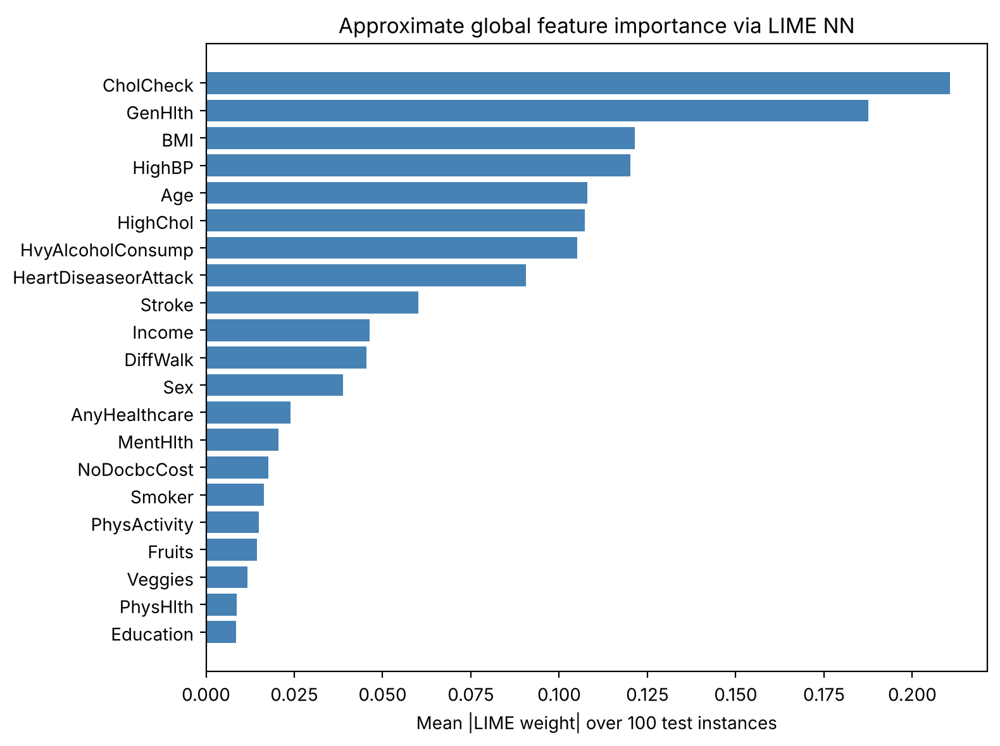

In [25]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(global_df['feature'][::-1], global_df['mean |LIME weight|'][::-1], color='steelblue')
ax.set_xlabel(f'Mean |LIME weight| over {N_EXPLAIN} test instances')
ax.set_title('Approximate global feature importance via LIME NN')
plt.tight_layout()
plt.show()

## 9. SHAP: interpreting the same model differently

**SHAP** (SHapley Additive exPlanations) computes each feature's contribution using Shapley values from cooperative game theory.

For a neural network we use **`shap.DeepExplainer`** (DeepSHAP):
- It combines Shapley values with **DeepLIFT**: contributions are propagated backwards through the layers, comparing each activation with its value for a set of **background** (reference) samples.
- It needs the model itself (PyTorch) and a background sample of inputs in the **scaled** space the network was trained on.
- To make SHAP values comparable with LIME (which explains probabilities), we append a `Sigmoid`, so the explained output is `P(prediabetes/diabetes)` instead of the logit.

**Key properties:**
- **Efficiency**: SHAP values sum to `f(x) − E[f(background)]`, the gap between the prediction and the average prediction on the background data.
- **Deterministic**: for a fixed background sample there is no sampling noise. A different background gives a different baseline and slightly different values.
- **Approximate**: DeepSHAP is a fast approximation of Shapley values, not the exact values.

In [26]:
import shap

# Explain the probability output: logits -> sigmoid
prob_model = nn.Sequential(model, nn.Sigmoid()).eval()

# Background (reference) data: a random sample of the scaled training data
N_BACKGROUND = 200
rng_bg = np.random.default_rng(SEED)
bg_idx = rng_bg.choice(len(X_train), size=N_BACKGROUND, replace=False)
background = torch.tensor(X_train[bg_idx], dtype=torch.float32)

deep_explainer = shap.DeepExplainer(prob_model, background)

def to_2d(shap_vals):
    # DeepExplainer returns a list, a 2-D or a 3-D array depending on the shap version
    if isinstance(shap_vals, list):
        shap_vals = shap_vals[0]
    shap_vals = np.asarray(shap_vals)
    if shap_vals.ndim == 3:
        shap_vals = shap_vals[:, :, 0]
    return shap_vals

# SHAP values for a 500-instance sample of the test set
N_SHAP = 500
sv_pos_all = to_2d(deep_explainer.shap_values(torch.tensor(X_test[:N_SHAP])))

expected_val = float(np.ravel(np.asarray(deep_explainer.expected_value))[0])

print(f'SHAP values shape : {sv_pos_all.shape}')
print(f'Baseline (E[f(X)]): {expected_val:.4f}')

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP values shape : (500, 21)
Baseline (E[f(X)]): 0.3655


In [27]:
# Check the efficiency property: baseline + sum of SHAP values ≈ predicted probability
f_x = predict_proba(X_test_raw[:N_SHAP])[:, 1]
reconstructed = expected_val + sv_pos_all.sum(axis=1)
print(f'Max |f(x) − (E[f(X)] + Σ SHAP)| over {N_SHAP} instances: {np.max(np.abs(f_x - reconstructed)):.2e}')

Max |f(x) − (E[f(X)] + Σ SHAP)| over 500 instances: 1.85e-07


### 9.1 Single-instance explanations with SHAP

A **waterfall plot** starts from the baseline `E[f(X)]` and adds each feature's contribution until it reaches the model's prediction `f(x)`.

- **Red bars** push the prediction *higher* (toward prediabetes/diabetes).
- **Blue bars** push it *lower*.
- The bars sum to `f(x) − E[f(X)]`.

The values shown next to the feature names are the original (unscaled) feature values.
Compare these with the LIME bar charts in sections 5–6: same instance, same model, different method.

Instance predicted as: Prediabetes/Diabetes (67.3%)


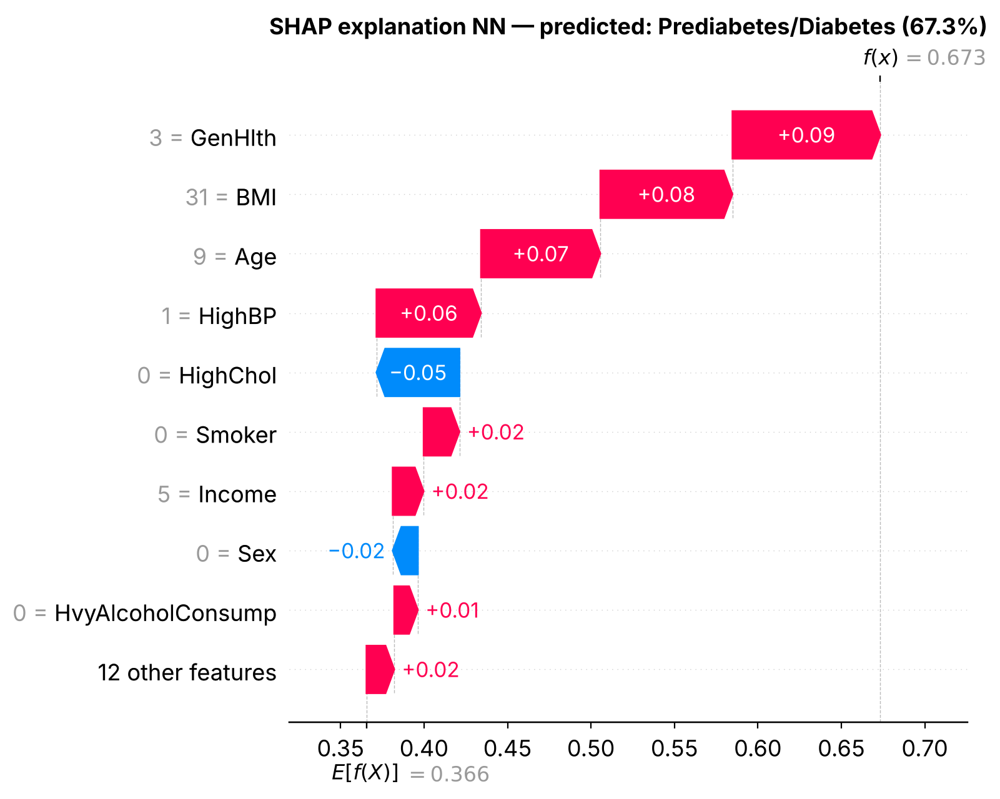

In [28]:
sv_hi_pos = to_2d(deep_explainer.shap_values(torch.tensor(X_test[idx:idx + 1])))[0]

shap_exp_hi = shap.Explanation(
    values=sv_hi_pos,
    base_values=expected_val,
    data=instance,
    feature_names=FEATURE_COLS,
)
print(f'Instance predicted as: {pred_class} ({pred_proba.max():.1%})')
shap.plots.waterfall(shap_exp_hi, show=False)
plt.title(f'SHAP explanation NN — predicted: {pred_class} ({pred_proba.max():.1%})',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

Instance predicted as: No diabetes (84.6%)


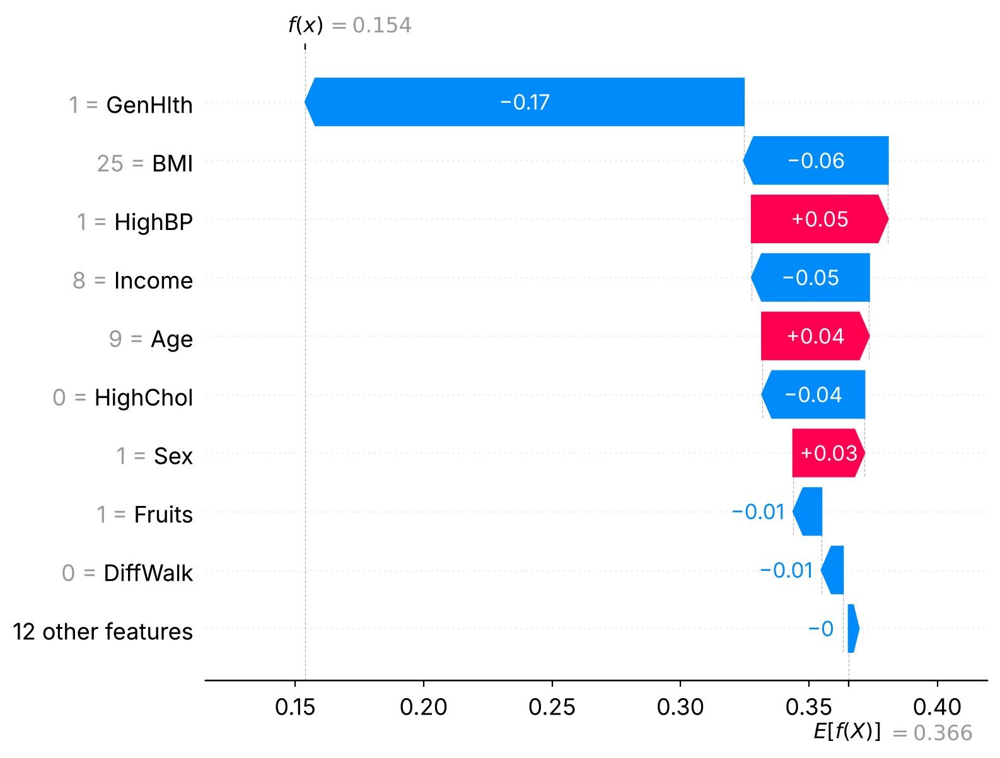

In [29]:
sv_lo_pos = to_2d(deep_explainer.shap_values(torch.tensor(X_test[idx2:idx2 + 1])))[0]

shap_exp_lo = shap.Explanation(
    values=sv_lo_pos,
    base_values=expected_val,
    data=instance2,
    feature_names=FEATURE_COLS,
)
print(f'Instance predicted as: {pred_class2} ({pred_proba2.max():.1%})')
shap.plots.waterfall(shap_exp_lo)

### 9.2 Global feature importance: the SHAP summary plot

Aggregating SHAP values over many instances gives a consistent global picture.

A **beeswarm plot** shows every instance as a dot. The x-axis is the SHAP value, and the colour encodes the raw feature value (red = high, blue = low). This shows not just *which* features matter, but also *how* their values relate to the predictions, which a simple bar chart can't show.

/tmp/ipykernel_938/256524370.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv_pos_all, X_test_raw[:N_SHAP], feature_names=FEATURE_COLS)


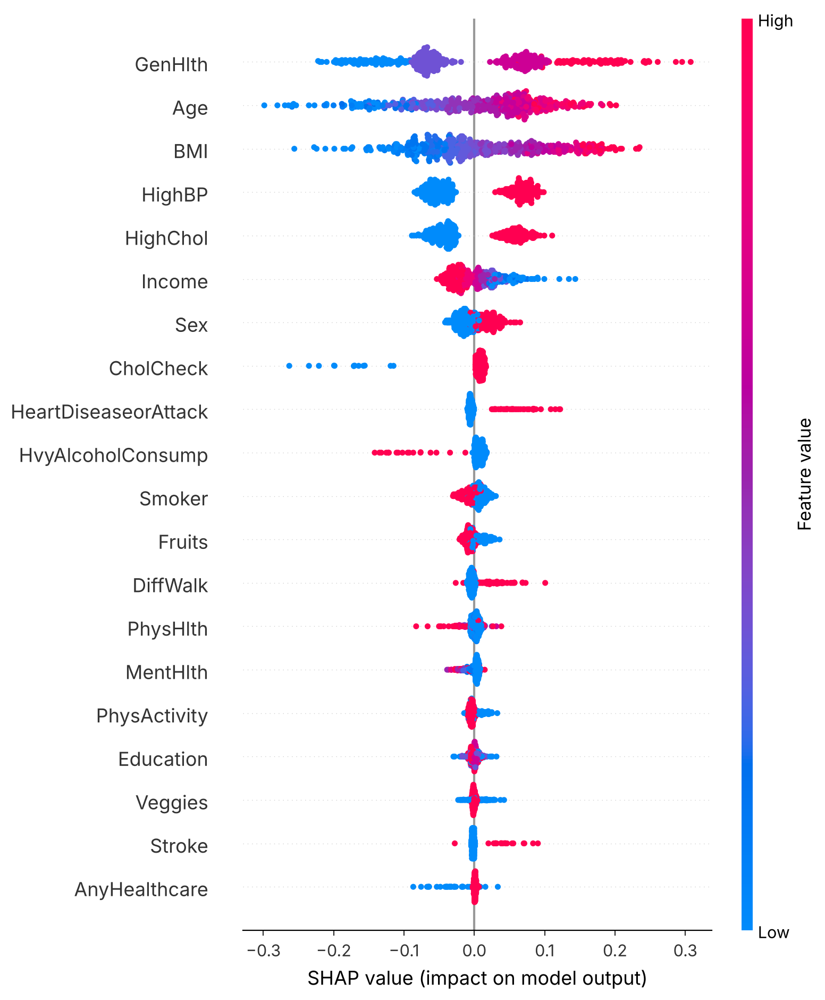

In [30]:
shap.summary_plot(sv_pos_all, X_test_raw[:N_SHAP], feature_names=FEATURE_COLS)

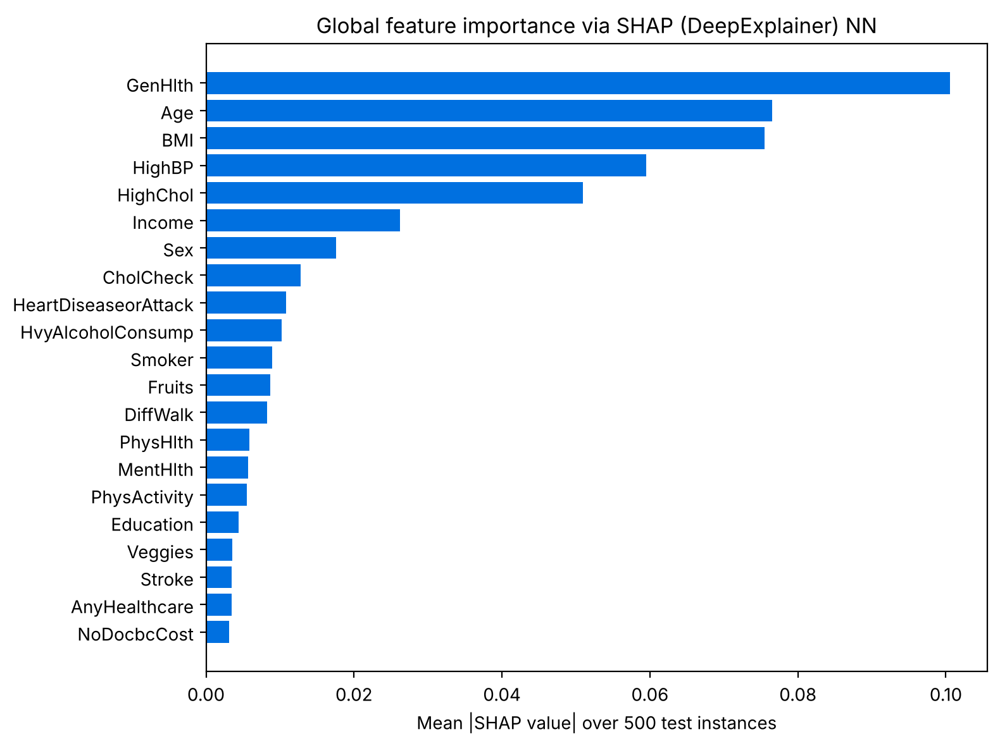

             feature  mean |SHAP|
             GenHlth     0.100575
                 Age     0.076535
                 BMI     0.075481
              HighBP     0.059484
            HighChol     0.050917
              Income     0.026247
                 Sex     0.017588
           CholCheck     0.012812
HeartDiseaseorAttack     0.010854
   HvyAlcoholConsump     0.010225
              Smoker     0.008972
              Fruits     0.008689
            DiffWalk     0.008226
            PhysHlth     0.005863
            MentHlth     0.005677
        PhysActivity     0.005484
           Education     0.004399
             Veggies     0.003590
              Stroke     0.003477
       AnyHealthcare     0.003463
         NoDocbcCost     0.003126


In [31]:
mean_abs_shap = np.mean(np.abs(sv_pos_all), axis=0)
shap_global_df = pd.DataFrame({
    'feature': FEATURE_COLS,
    'mean |SHAP|': mean_abs_shap,
}).sort_values('mean |SHAP|', ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(shap_global_df['feature'][::-1], shap_global_df['mean |SHAP|'][::-1], color="#0070e0")
ax.set_xlabel(f'Mean |SHAP value| over {N_SHAP} test instances')
ax.set_title('Global feature importance via SHAP (DeepExplainer) NN')
plt.tight_layout()
plt.show()
print(shap_global_df.to_string(index=False))

## 10. LIME vs SHAP: side-by-side comparison

Both methods attribute a prediction to its features, but they use different mechanisms. Here we compare them directly on **the same instance** and on **the same global ranking**.

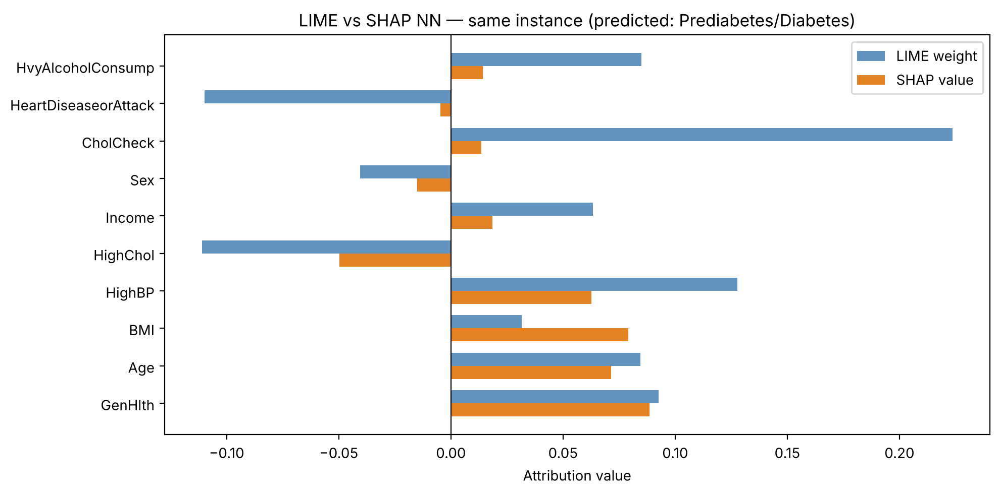

In [32]:
# LIME weights for the positive instance -> map to feature names
lime_by_feature = {FEATURE_COLS[i]: w for i, w in exp.as_map()[pos_label]}

# SHAP values for the same instance
shap_by_feature = dict(zip(FEATURE_COLS, sv_hi_pos))

# Compare over the top-10 features by mean |SHAP| (global ranking)
top10 = shap_global_df['feature'].head(10).tolist()
lime_local = [lime_by_feature.get(f, 0) for f in top10]
shap_local = [shap_by_feature[f] for f in top10]

x = np.arange(len(top10))
bar_w = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(x + bar_w/2, lime_local, bar_w, label='LIME weight', color='steelblue', alpha=0.85)
ax.barh(x - bar_w/2, shap_local, bar_w, label='SHAP value', color='#e06c00', alpha=0.85)
ax.set_yticks(x)
ax.set_yticklabels(top10)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Attribution value')
ax.set_title(f'LIME vs SHAP NN — same instance (predicted: {pred_class})')
ax.legend()
plt.tight_layout()
plt.show()

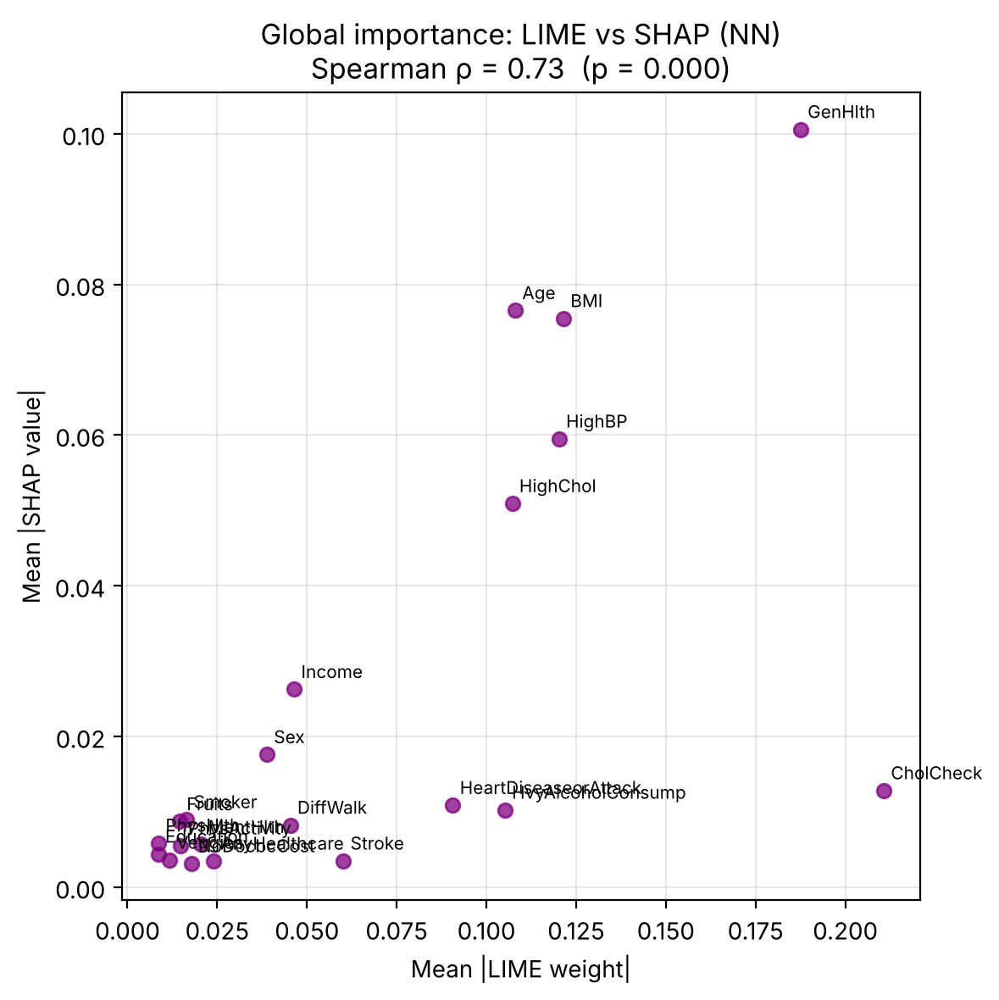

Spearman rank correlation: ρ = 0.730,  p = 0.0002


In [33]:
from scipy.stats import spearmanr

# Align global rankings by feature name
lime_series = global_df.set_index('feature')['mean |LIME weight|']
shap_series = shap_global_df.set_index('feature')['mean |SHAP|']
aligned = pd.DataFrame({'LIME': lime_series, 'SHAP': shap_series}).dropna()

rho, pval = spearmanr(aligned['LIME'], aligned['SHAP'])

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(aligned['LIME'], aligned['SHAP'], color='purple', alpha=0.75, zorder=3)
for feat, row in aligned.iterrows():
    ax.annotate(feat, (row['LIME'], row['SHAP']), fontsize=7.5, ha='left', va='bottom',
                xytext=(3, 3), textcoords='offset points')
ax.set_xlabel('Mean |LIME weight|')
ax.set_ylabel('Mean |SHAP value|')
ax.set_title(f'Global importance: LIME vs SHAP ({MODEL_TAG})\nSpearman ρ = {rho:.2f}  (p = {pval:.3f})')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print(f'Spearman rank correlation: ρ = {rho:.3f},  p = {pval:.4f}')

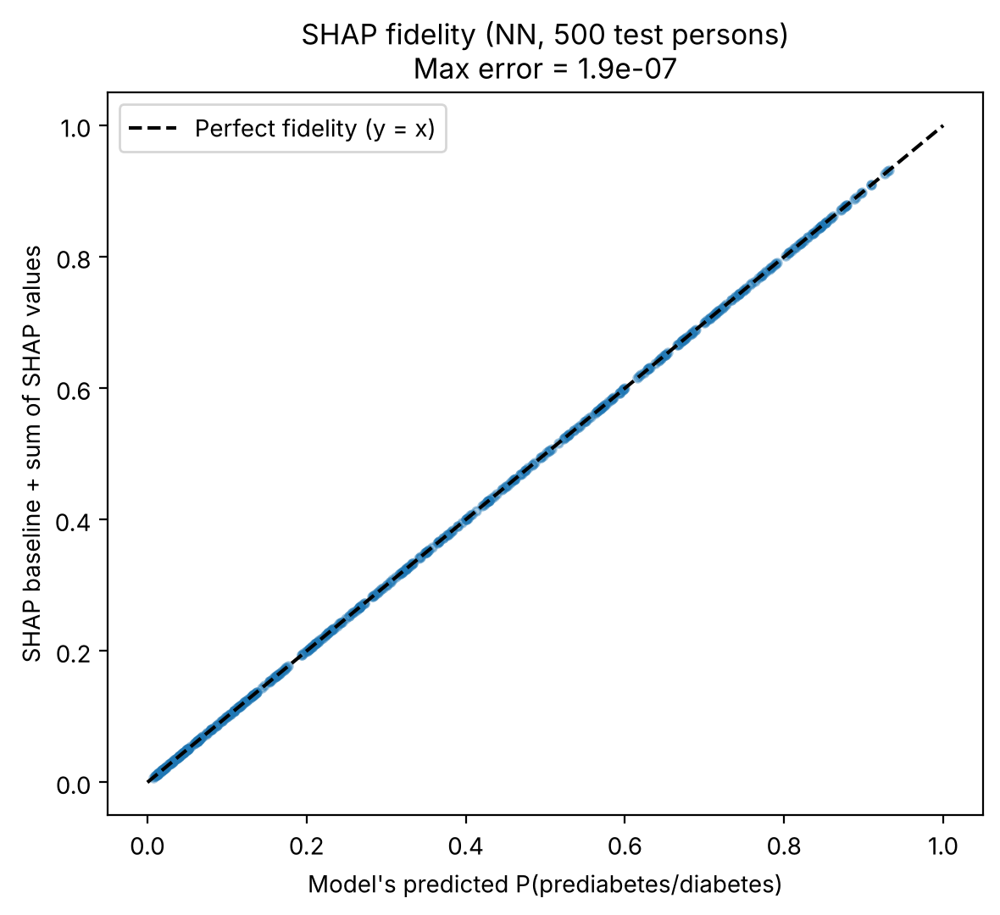

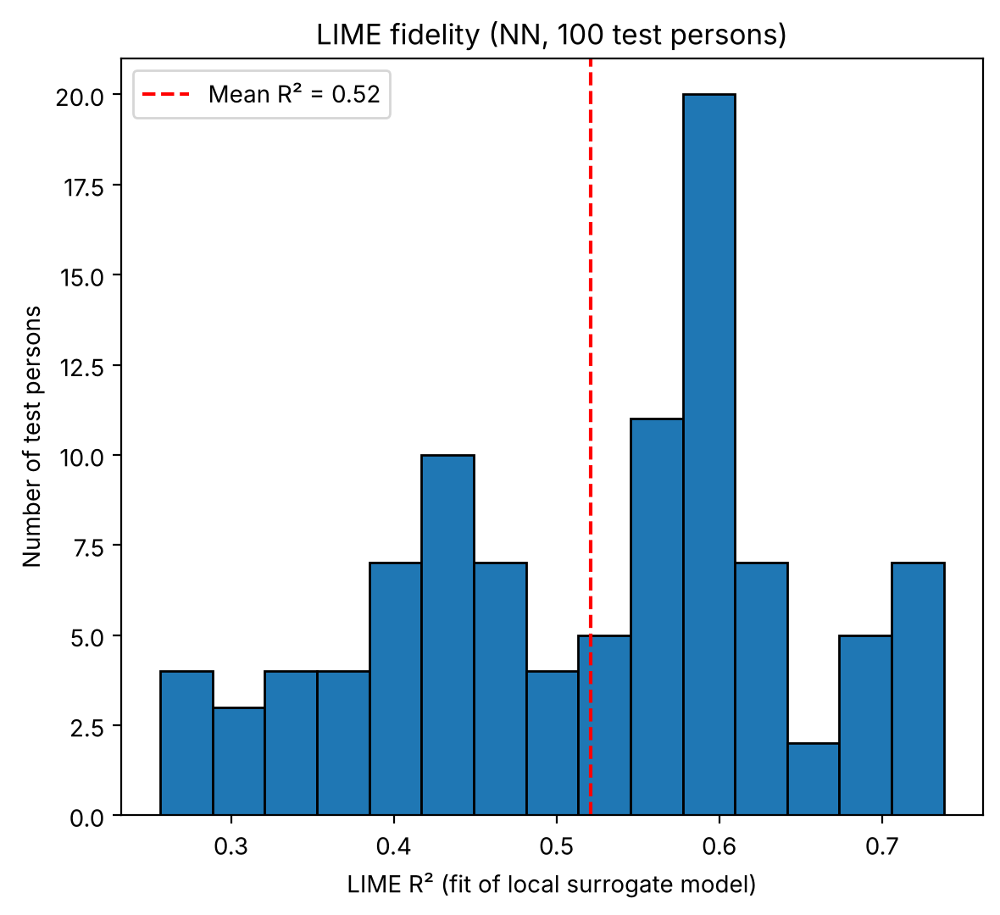

SHAP max error: 1.9e-07
LIME mean R²:   0.52  (min 0.26, max 0.74)


In [34]:
# ===== Fidelity: SHAP vs LIME =====

# --- Plot 1: SHAP additivity (uses f_x and reconstructed from section 9) ---
max_err = np.max(np.abs(f_x - reconstructed))

plt.figure(figsize=(6, 5.5))
plt.scatter(f_x, reconstructed, alpha=0.4, s=12)
plt.plot([0, 1], [0, 1], 'k--', label='Perfect fidelity (y = x)')
plt.xlabel("Model's predicted P(prediabetes/diabetes)")
plt.ylabel('SHAP baseline + sum of SHAP values')
plt.title(f'SHAP fidelity (NN, {N_SHAP} test persons)\nMax error = {max_err:.1e}')
plt.legend()
plt.tight_layout()
plt.savefig('fidelity_shap_nn.png', dpi=200)
plt.show()

# --- Plot 2: LIME R² across test persons ---
lime_r2 = []
for i in sample_idx:                  # same 100 test persons as section 8
    e = explainer.explain_instance(
        data_row=X_test_raw[i],
        predict_fn=predict_proba,
        num_features=len(FEATURE_COLS),
        num_samples=5000,
    )
    lime_r2.append(e.score)           # R² of LIME's local linear model

lime_r2 = np.array(lime_r2)

plt.figure(figsize=(6, 5.5))
plt.hist(lime_r2, bins=15, edgecolor='black')
plt.axvline(lime_r2.mean(), color='red', linestyle='--',
            label=f'Mean R² = {lime_r2.mean():.2f}')
plt.xlabel('LIME R² (fit of local surrogate model)')
plt.ylabel('Number of test persons')
plt.title(f'LIME fidelity (NN, {len(lime_r2)} test persons)')
plt.legend()
plt.tight_layout()
plt.savefig('fidelity_lime_nn.png', dpi=200)
plt.show()

print(f'SHAP max error: {max_err:.1e}')
print(f'LIME mean R²:   {lime_r2.mean():.2f}  (min {lime_r2.min():.2f}, max {lime_r2.max():.2f})')

People with prediabetes/diabetes in test set: 7995
  Found (true positives):   6263
  Missed (false negatives): 1732

                      False negative (#22542)  True positive (#16882)
HighBP                                    0.0                     1.0
HighChol                                  0.0                     0.0
CholCheck                                 1.0                     1.0
BMI                                      20.0                    36.0
Smoker                                    0.0                     0.0
Stroke                                    0.0                     0.0
HeartDiseaseorAttack                      0.0                     0.0
PhysActivity                              1.0                     0.0
Fruits                                    1.0                     1.0
Veggies                                   1.0                     1.0
HvyAlcoholConsump                         0.0                     0.0
AnyHealthcare                             

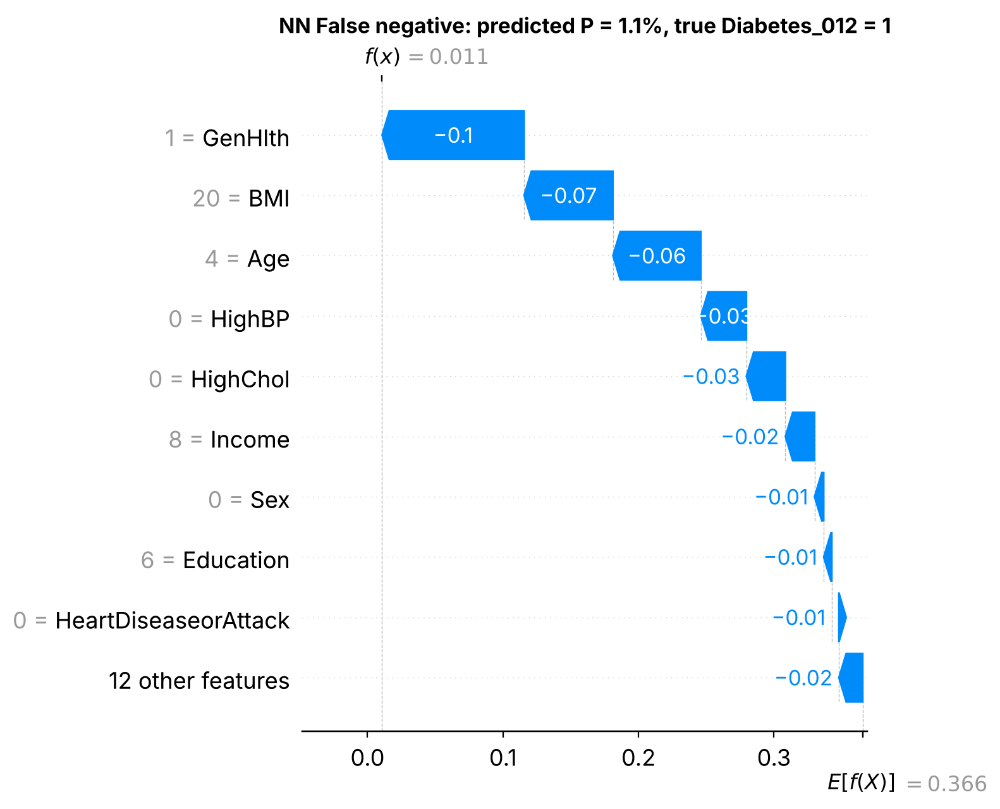

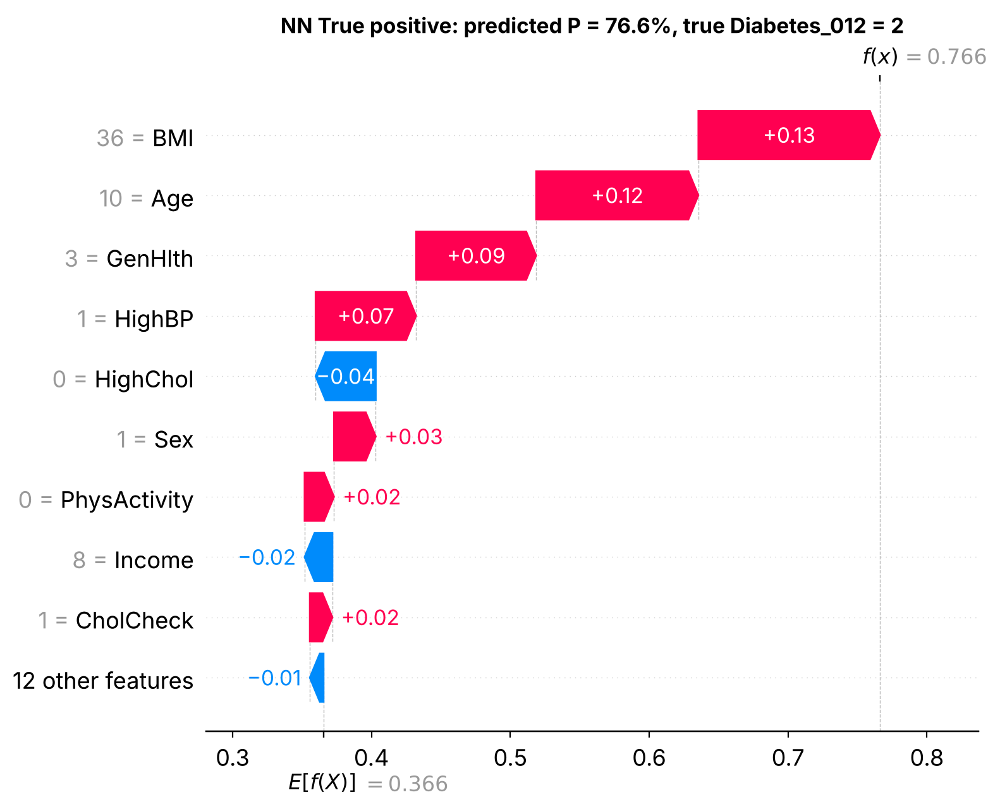

In [35]:
# ===== Local SHAP: false negative vs true positive =====

# People who HAVE prediabetes/diabetes, split by whether the model caught them
fn_idx = np.where((test_pred == 0) & (y_test == 1))[0]   # missed
tp_idx = np.where((test_pred == 1) & (y_test == 1))[0]   # found
print(f'People with prediabetes/diabetes in test set: {int(np.sum(y_test == 1))}')
print(f'  Found (true positives):   {len(tp_idx)}')
print(f'  Missed (false negatives): {len(fn_idx)}\n')

# False negative: the most confident miss (lowest predicted risk)
idx_fn = fn_idx[np.argmin(test_proba[fn_idx])]

# True positive: a typical hit (predicted risk closest to the median of all hits)
median_tp = np.median(test_proba[tp_idx])
idx_tp = tp_idx[np.argmin(np.abs(test_proba[tp_idx] - median_tp))]

# Feature values side by side
cases = pd.DataFrame({
    f'False negative (#{idx_fn})': X_test_raw[idx_fn],
    f'True positive (#{idx_tp})': X_test_raw[idx_tp],
}, index=FEATURE_COLS)
print(cases.to_string())

# SHAP waterfall for each case
for name, i in [('False negative', idx_fn), ('True positive', idx_tp)]:
    sv_i = to_2d(deep_explainer.shap_values(torch.tensor(X_test[i:i + 1])))[0]
    exp_i = shap.Explanation(values=sv_i, base_values=expected_val,
                             data=X_test_raw[i], feature_names=FEATURE_COLS)
    shap.plots.waterfall(exp_i, max_display=10, show=False)
    plt.title(f'NN {name}: predicted P = {test_proba[i]:.1%}, true Diabetes_012 = {y012_test[i]}',
              fontsize=12, fontweight='bold')
    plt.tight_layout()
    file_name = 'shap_' + name.lower().replace(' ', '_') + '_nn.png'
    plt.savefig(file_name, dpi=200, bbox_inches='tight')
    plt.show()

## 11. Latent space: PCA, t-SNE and UMAP (new in Project 2)

The network maps every person to a 16-dimensional vector in its **last hidden layer** (after the second ReLU). The output layer is just a linear classifier on top of this vector, so this is the representation the network has *learned* to make its decision.

We take a random sample of test persons, extract their 16-dimensional hidden vectors and project them to 2-D with three methods:

| Method | Type | What it preserves |
|---|---|---|
| **PCA** | linear | the directions of largest variance; distances are meaningful |
| **t-SNE** | non-linear | local neighbourhoods; distances between clusters and cluster sizes are *not* meaningful |
| **UMAP** | non-linear | local neighbourhoods and some of the global structure |

Each plot is coloured twice: by the **true 3-class label** (`Diabetes_012`, so we can see where prediabetes ends up) and by the **model's predicted probability**.

### 11.1 Extract the hidden-layer activations

In [36]:
# model.network = [Linear(21,32), ReLU, Linear(32,16), ReLU, Linear(16,1)]
# model.network[:4] stops after the second ReLU -> one 16-dimensional vector per person
LATENT_NAME = 'last hidden layer (16 units)'

N_LATENT = 5000   # t-SNE and UMAP are slow on the full test set, so we use a random sample
rng_lat = np.random.default_rng(SEED)
lat_idx = rng_lat.choice(len(X_test), size=N_LATENT, replace=False)

model.eval()
with torch.no_grad():
    H = model.network[:4](torch.tensor(X_test[lat_idx])).numpy()

lat_y012 = y012_test[lat_idx]     # true 3-class label of the sampled persons
lat_proba = test_proba[lat_idx]   # model's predicted probability

print('Hidden representation shape:', H.shape)
print('Hidden units that are 0 for every sampled person ("dead" ReLUs):', int(np.sum(H.max(axis=0) == 0)))
print('Classes in the sample (0, 1, 2):', np.bincount(lat_y012))

Hidden representation shape: (5000, 16)
Hidden units that are 0 for every sampled person ("dead" ReLUs): 0
Classes in the sample (0, 1, 2): [4232   92  676]


### 11.2 Compute the three 2-D embeddings

In [37]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

# --- PCA: linear projection onto the 2 directions with the most variance ---
pca = PCA(n_components=2, random_state=SEED)
emb_pca = pca.fit_transform(H)
print('PCA explained variance ratio (PC1, PC2):', pca.explained_variance_ratio_.round(3))

# --- t-SNE: non-linear, keeps local neighbourhoods ---
tsne = TSNE(n_components=2, perplexity=30, init='pca', random_state=SEED)
emb_tsne = tsne.fit_transform(H)
print('t-SNE done')

# --- UMAP: non-linear, keeps local neighbourhoods and (some) global structure ---
reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=SEED)
emb_umap = reducer.fit_transform(H)
print('UMAP done')

PCA explained variance ratio (PC1, PC2): [0.753 0.085]


t-SNE done


/usr/local/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP done


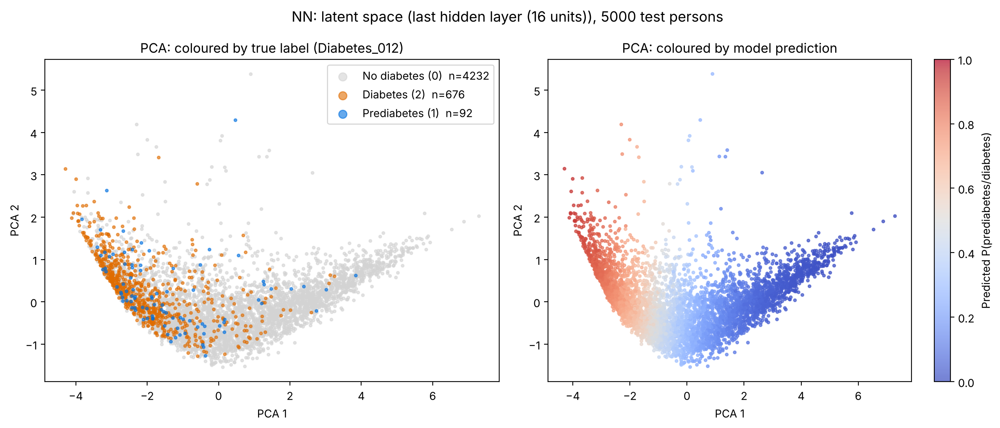

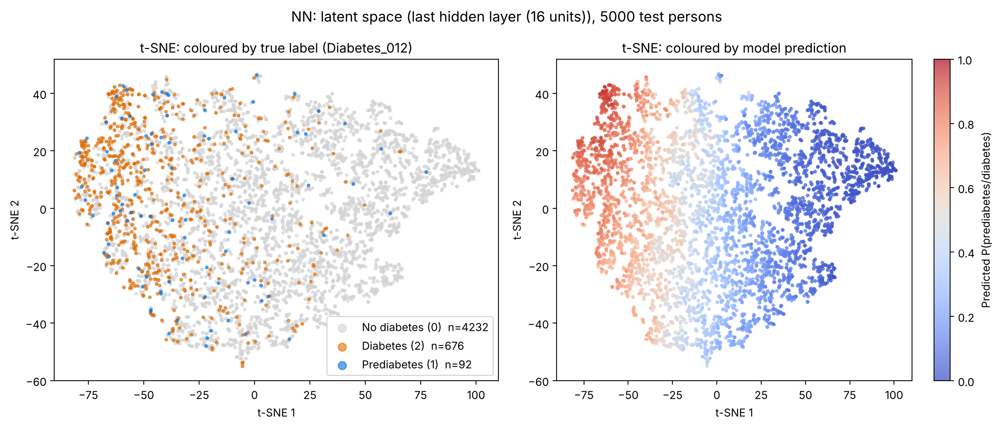

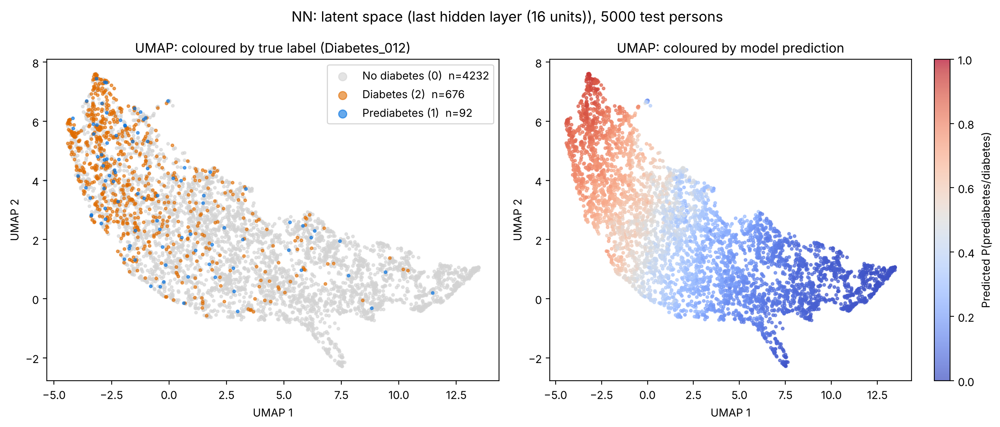

In [38]:
class_colors = {0: 'lightgray', 1: '#0070e0', 2: '#e06c00'}
class_labels = {0: 'No diabetes (0)', 1: 'Prediabetes (1)', 2: 'Diabetes (2)'}

embeddings = [(emb_pca, 'PCA'), (emb_tsne, 't-SNE'), (emb_umap, 'UMAP')]

for emb, method_name in embeddings:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

    # Left: true 3-class label. The big class is drawn first so the small classes stay visible on top.
    for c in [0, 2, 1]:
        mask = lat_y012 == c
        axes[0].scatter(emb[mask, 0], emb[mask, 1], s=6, alpha=0.6, color=class_colors[c],
                        label=f'{class_labels[c]}  n={mask.sum()}')
    axes[0].set_title(f'{method_name}: coloured by true label (Diabetes_012)')
    axes[0].legend(markerscale=3, loc='best')

    # Right: the model's predicted probability
    sc = axes[1].scatter(emb[:, 0], emb[:, 1], c=lat_proba, cmap='coolwarm', vmin=0, vmax=1, s=6, alpha=0.7)
    plt.colorbar(sc, ax=axes[1], label='Predicted P(prediabetes/diabetes)')
    axes[1].set_title(f'{method_name}: coloured by model prediction')

    for ax in axes:
        ax.set_xlabel(f'{method_name} 1')
        ax.set_ylabel(f'{method_name} 2')

    fig.suptitle(f'{MODEL_TAG}: latent space ({LATENT_NAME}), {N_LATENT} test persons', fontsize=13)
    plt.tight_layout()
    plt.savefig(f'latent_{method_name.lower().replace("-", "")}_{MODEL_TAG.lower().replace(" ", "")}.png', dpi=200)
    plt.show()

### 11.3 Which concepts are encoded in the latent space?

To see *what* the representation is organised by, we colour the same embeddings by single input features. A feature whose colour changes smoothly across the plot is strongly encoded in the representation. Socio-economic features (`Income`, `Education`) and `Sex` are included on purpose, because they are not medical causes of diabetes.

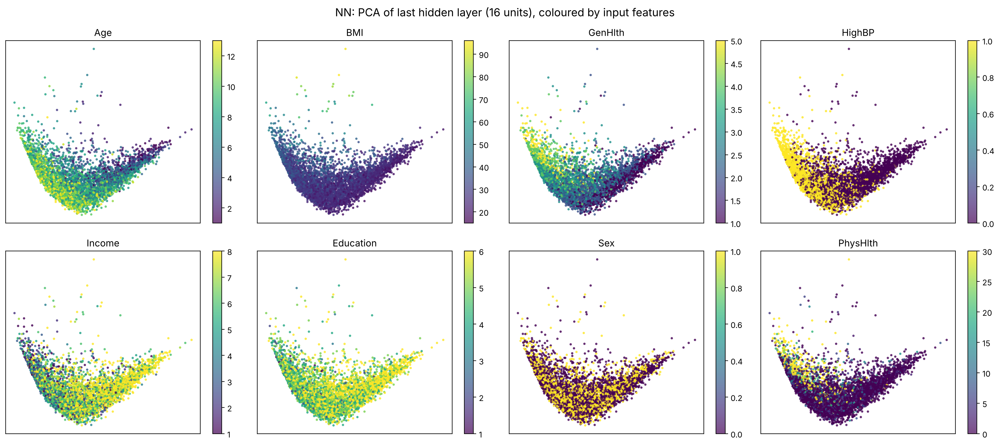

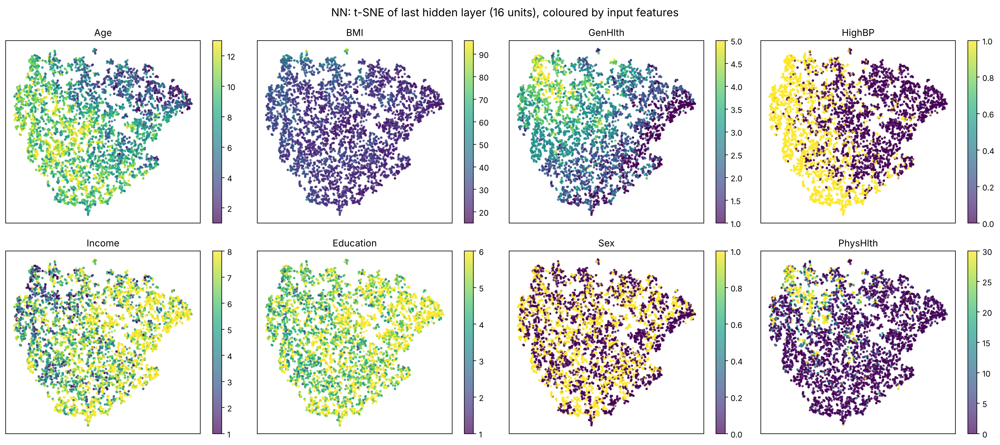

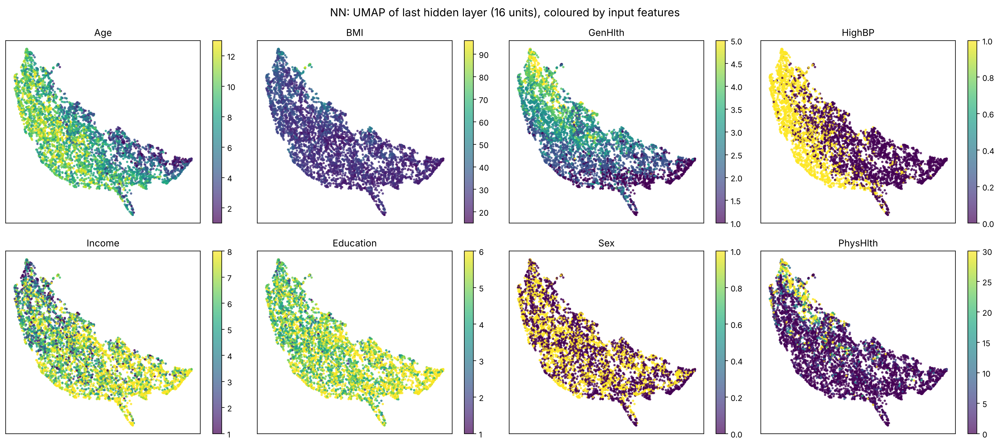

In [39]:
concept_features = ['Age', 'BMI', 'GenHlth', 'HighBP', 'Income', 'Education', 'Sex', 'PhysHlth']
lat_raw = X_test_raw[lat_idx]

for emb, method_name in embeddings:
    fig, axes = plt.subplots(2, 4, figsize=(18, 8))
    for ax, feat in zip(axes.ravel(), concept_features):
        values = lat_raw[:, FEATURE_COLS.index(feat)]
        sc = ax.scatter(emb[:, 0], emb[:, 1], c=values, cmap='viridis', s=4, alpha=0.7)
        plt.colorbar(sc, ax=ax)
        ax.set_title(feat)
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(f'{MODEL_TAG}: {method_name} of {LATENT_NAME}, coloured by input features', fontsize=14)
    plt.tight_layout()
    plt.savefig(f'latent_concepts_{method_name.lower().replace("-", "")}_{MODEL_TAG.lower().replace(" ", "")}.png', dpi=200)
    plt.show()

### Questions to think about for the audit
- Where do the **prediabetes** points lie: among the diabetes points, among the no-diabetes points, or somewhere in between? What does that tell you about how hard this class is to detect?
- Do PCA, t-SNE and UMAP tell the same story? Which structures appear in all three, and which appear only in one of them? (Remember: in t-SNE and UMAP, distances *between* clusters and cluster sizes are not reliable.)
- Which input features change smoothly across the embedding? Are any of them **non-medical** (Income, Education, Sex)? Would it be a problem for deployment if the model's representation is organised by them?
- Compare with the other model's notebook: does the neural network learn a representation that differs from the logistic regression's weighted inputs?